# Foundations of Data Science
## Tutorial 7 — Three classifiers from scratch on MNIST · **Solutions**

Worked solutions for all `# your code here` exercises in `tutorial07_classifiers_from_scratch.ipynb`. The non-exercise cells are identical, so this notebook runs end-to-end.

1. **The Perceptron** (Rosenblatt, 1958)
2. **The Soft-Margin SVM** trained by stochastic gradient descent on the hinge loss
3. **A small multi-layer perceptron (MLP)** trained by back-propagation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (9, 4)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/home/david/miniconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/home/david/miniconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/home/david/miniconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 739, in start
    self.io_loop.start()
  File "/home/david

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/home/david/miniconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/home/david/miniconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/home/david/miniconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 739, in start
    self.io_loop.start()
  File "/home/david

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



## Load & split the data

1,797 grayscale images, 8×8 pixels. We flatten each image to a 64-dimensional vector and scale pixel values to $[0, 1]$. Then a random 80/20 train/test split.

train: (1437, 64), test: (360, 64)


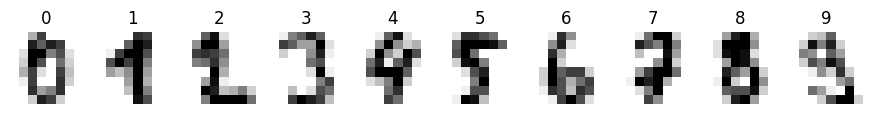

In [2]:
digits = load_digits()
X_all = digits.data.astype(float) / 16.0     # pixel values 0..16 → 0..1
y_all = digits.target                        # labels 0..9

n = len(X_all)
perm = rng.permutation(n)
n_tr = int(0.8 * n)
X_train, X_test = X_all[perm[:n_tr]], X_all[perm[n_tr:]]
y_train, y_test = y_all[perm[:n_tr]], y_all[perm[n_tr:]]
print(f"train: {X_train.shape}, test: {X_test.shape}")

# Quick visual sanity check
fig, axes = plt.subplots(1, 10, figsize=(11, 1.6))
for i, ax in enumerate(axes):
    idx = np.where(y_train == i)[0][0]
    ax.imshow(X_train[idx].reshape(8, 8), cmap="gray_r")
    ax.set_title(str(i)); ax.axis("off")
plt.show()

## Part 1 — The Perceptron

The Rosenblatt perceptron is the simplest neural network: a single linear unit. For binary labels $y_i \in \{-1, +1\}$ and an input $x_i \in \mathbb{R}^d$, the prediction is
$$ \hat y_i = \mathrm{sign}(w^\top x_i + b) $$

The training rule is breathtakingly simple: go through the data, and **whenever you make a mistake, nudge the weights toward the correct answer**.

$$ \text{if } y_i (w^\top x_i + b) \leq 0:\ \ w \leftarrow w + \eta\, y_i\, x_i,\quad b \leftarrow b + \eta\, y_i $$

**Theorem (Novikoff, 1962):** if the data is linearly separable, the perceptron converges in finitely many updates. If the data is *not* separable, it keeps cycling forever.

We'll fold the bias into $w$ by adding a constant 1 column to $X$.

In [3]:
def fit_perceptron(X, y, n_epochs=30, lr=1.0):
    """y must be ±1. Returns w (bias is w[0]) and history of #mistakes per epoch."""
    n, d = X.shape
    X_aug = np.column_stack([np.ones(n), X])     # prepend bias column
    w = np.zeros(d + 1)
    history = []
    for _ in range(n_epochs):
        errors = 0
        for i in range(n):
            if y[i] * (X_aug[i] @ w) <= 0:        # mistake → update
                w += lr * y[i] * X_aug[i]
                errors += 1
        history.append(errors)
        if errors == 0:                          # converged
            break
    return w, history

def predict_perceptron(X, w):
    X_aug = np.column_stack([np.ones(len(X)), X])
    return np.sign(X_aug @ w)

### Train on 0 vs 1 — an easy pair

0s and 1s look very different visually, so the binary problem should be cleanly separable. Encode 0 → −1, 1 → +1.

In [4]:
def make_binary(X, y, neg_class, pos_class):
    mask = (y == neg_class) | (y == pos_class)
    Xb = X[mask]
    yb = np.where(y[mask] == pos_class, 1, -1)
    return Xb, yb

X01_tr, y01_tr = make_binary(X_train, y_train, 0, 1)
X01_te, y01_te = make_binary(X_test,  y_test,  0, 1)
print(f"train pairs: {len(y01_tr)}, test pairs: {len(y01_te)}")

w01, history01 = fit_perceptron(X01_tr, y01_tr)

train_acc = np.mean(predict_perceptron(X01_tr, w01) == y01_tr)
test_acc  = np.mean(predict_perceptron(X01_te, w01) == y01_te)
print(f"train accuracy: {train_acc*100:.2f}%")
print(f"test  accuracy: {test_acc*100:.2f}%")
print(f"converged after {len(history01)} epochs (errors per epoch: {history01})")

train pairs: 284, test pairs: 76
train accuracy: 100.00%
test  accuracy: 100.00%
converged after 3 epochs (errors per epoch: [6, 2, 0])


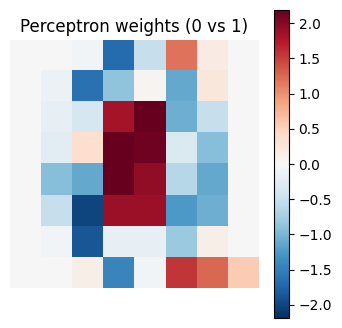

In [5]:
# Visualize the learned weights as an image — red = pushes toward +1 (digit 1)
weight_img = w01[1:].reshape(8, 8)
plt.figure(figsize=(4, 4))
vmax = np.abs(weight_img).max()
plt.imshow(weight_img, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
plt.colorbar()
plt.title("Perceptron weights (0 vs 1)")
plt.axis("off")
plt.show()

**Read the weight image:** Red pixels push the prediction toward digit 1 — these are the pixels that fire when a 1 is drawn (mostly the vertical center). Blue pixels push toward 0 — the rim and corners, where a 0's outline lives but a 1 has no ink. The perceptron has learned a sensible template.

### Exercise 7.0 — Perceptron on 3 vs 5 · **Solution**

Try the perceptron on a harder pair: **3 vs 5**. These digits share more pixels in common, so the problem isn't as cleanly separable.

1. Build the binary 3-vs-5 train/test sets.
2. Run `fit_perceptron` for 50 epochs and look at `history`. Does it converge to zero errors? If not — does the error stabilize, or jump around?
3. Report train and test accuracy.
4. Plot the learned weights as an image.

train pairs: 305, test pairs: 60
train accuracy: 100.00%
test  accuracy: 100.00%
ran 4 epochs (converged early if < 50)
mistakes per epoch: [25, 8, 4, 0]


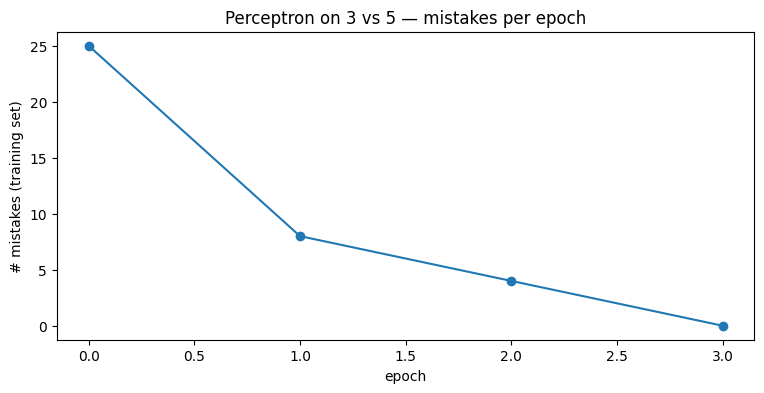

In [6]:
# 1. Binary 3-vs-5 sets:  3 -> -1,  5 -> +1
X35_tr, y35_tr = make_binary(X_train, y_train, 3, 5)
X35_te, y35_te = make_binary(X_test,  y_test,  3, 5)
print(f"train pairs: {len(y35_tr)}, test pairs: {len(y35_te)}")

# 2. Train for 50 epochs and inspect the per-epoch mistake count
w35, history35 = fit_perceptron(X35_tr, y35_tr, n_epochs=50)

# 3. Accuracies
train_acc = np.mean(predict_perceptron(X35_tr, w35) == y35_tr)
test_acc  = np.mean(predict_perceptron(X35_te, w35) == y35_te)
print(f"train accuracy: {train_acc*100:.2f}%")
print(f"test  accuracy: {test_acc*100:.2f}%")
print(f"ran {len(history35)} epochs (converged early if < 50)")
print("mistakes per epoch:", history35)

# Visualize how the mistake count evolves
plt.figure()
plt.plot(history35, "o-")
plt.xlabel("epoch"); plt.ylabel("# mistakes (training set)")
plt.title("Perceptron on 3 vs 5 — mistakes per epoch")
plt.show()

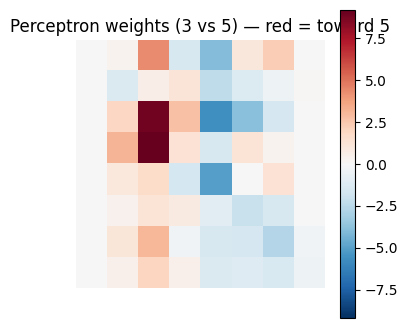

In [7]:
# 4. Learned weights as an 8x8 image — red pushes toward +1 (digit 5)
weight_img = w35[1:].reshape(8, 8)
plt.figure(figsize=(4, 4))
vmax = np.abs(weight_img).max()
plt.imshow(weight_img, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
plt.colorbar()
plt.title("Perceptron weights (3 vs 5) — red = toward 5")
plt.axis("off")
plt.show()

**Discussion.** The honest answer on *this* split is a small surprise: even 3-vs-5 turns out to be **linearly separable** in raw 64-dimensional pixel space, so the perceptron *does* converge to zero training errors — here in 4 epochs (`mistakes per epoch [25, 8, 4, 0]`), reaching 100% train and 100% test accuracy.

What *is* harder than 0-vs-1 shows up in the **path to convergence**, not the endpoint. The first epoch makes far more mistakes (≈25 vs ≈6 for 0-vs-1) and it needs an extra epoch to settle, because 3 and 5 overlap heavily in pixel space — the separating margin is thin, so the perceptron has to nudge the weights many more times before every point lands on the correct side. The reason separability holds at all is the **high dimension**: with 64 features and only a few hundred points, a separating hyperplane almost always exists (recall the high-dimensional geometry from Tutorial 2), even when the classes look visually similar.

The weight image is correspondingly **noisier** than the clean 0-vs-1 template: the discriminative ink concentrates in the upper-stroke / top-left region — a 5 has a flat top bar with an open top-left, whereas a 3 curves there — but red/blue contrast is weaker because the digits share so many pixels. The catch is that a perceptron solution is *some* separator, not the *best* one; if you reran with a different split (or moved to the full 28×28 MNIST, where 3-vs-5 is genuinely non-separable) it would stop converging and the mistake count would bounce around a non-zero floor. That fragility is exactly what the SVM's margin objective in Part 2 is designed to fix.

## Part 2 — Soft-Margin SVM via SGD on the hinge loss

The perceptron just wants *some* separating hyperplane. The SVM additionally asks for the **widest possible margin** — and tolerates a few violations on data that isn't perfectly separable.

The soft-margin SVM primal is
$$ \min_{w, b}\ \tfrac{1}{2}\|w\|^2 + C \sum_{i=1}^{n} \max\!\big(0,\ 1 - y_i(w^\top x_i + b)\big) $$

The second term is the **hinge loss** — zero if the example is on the correct side of the margin, otherwise linear in how badly it's violated.

**Stochastic subgradient descent** on a random sample $(x_i, y_i)$:
- If $y_i(w^\top x_i + b) < 1$ (margin violated): $w \leftarrow w - \eta(w - C\, y_i x_i)$, $b \leftarrow b + \eta\, C\, y_i$.
- Otherwise: $w \leftarrow w - \eta\, w$ (just shrink toward zero).

We don't regularize the bias.

In [8]:
def fit_svm_sgd(X, y, C=1.0, n_epochs=100, lr=0.01, rng=None):
    """Soft-margin SVM via stochastic subgradient descent. y in ±1."""
    rng = rng or np.random.default_rng(0)
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    losses = []
    for _ in range(n_epochs):
        for i in rng.permutation(n):
            margin = y[i] * (X[i] @ w + b)
            if margin < 1:
                w -= lr * (w - C * y[i] * X[i])
                b += lr * C * y[i]
            else:
                w -= lr * w
        # Track full objective at the end of each epoch
        hinge = np.maximum(0, 1 - y * (X @ w + b)).sum()
        losses.append(0.5 * np.dot(w, w) + C * hinge)
    return w, b, losses

def predict_svm(X, w, b):
    return np.sign(X @ w + b)

### Train on the harder 3-vs-5 pair

Let's directly attack the pair that gave the perceptron trouble.

SVM   train accuracy: 97.05%
SVM   test  accuracy: 98.33%


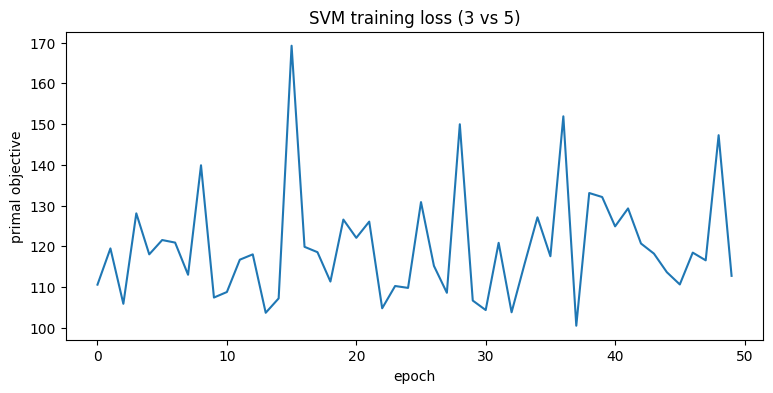

In [9]:
X35_tr, y35_tr = make_binary(X_train, y_train, 3, 5)
X35_te, y35_te = make_binary(X_test,  y_test,  3, 5)

w_svm, b_svm, losses = fit_svm_sgd(X35_tr, y35_tr, C=1.0, n_epochs=50,
                                    lr=0.01, rng=np.random.default_rng(1))

train_acc = np.mean(predict_svm(X35_tr, w_svm, b_svm) == y35_tr)
test_acc  = np.mean(predict_svm(X35_te, w_svm, b_svm) == y35_te)
print(f"SVM   train accuracy: {train_acc*100:.2f}%")
print(f"SVM   test  accuracy: {test_acc*100:.2f}%")

plt.figure()
plt.plot(losses)
plt.xlabel("epoch"); plt.ylabel("primal objective")
plt.title("SVM training loss (3 vs 5)")
plt.show()

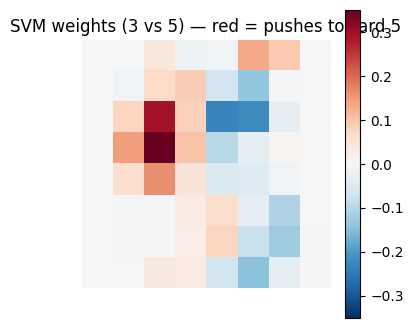

In [10]:
weight_img = w_svm.reshape(8, 8)
plt.figure(figsize=(4, 4))
vmax = np.abs(weight_img).max()
plt.imshow(weight_img, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
plt.colorbar()
plt.title("SVM weights (3 vs 5) — red = pushes toward 5")
plt.axis("off")
plt.show()

### Exercise 7.1 — the role of C · **Solution**

$C$ controls the trade-off between *margin width* and *margin violations*:
- Small $C$ → emphasis on $\|w\|^2$ (wide margin, tolerant of mistakes)
- Large $C$ → emphasis on hinge loss (narrow margin, fewer violations)

1. Train SVMs on the 3-vs-5 data for $C \in \{0.01, 0.1, 1.0, 10.0, 100.0\}$.
2. For each $C$, record the training accuracy, test accuracy, and $\|w\|$.
3. Plot accuracy vs $\log C$. Where's the sweet spot? What happens to $\|w\|$ as $C$ grows?

       C    train     test    ||w||
    0.01   50.82%   46.67%    0.009
    0.10   50.82%   46.67%    0.093
    1.00   97.05%   98.33%    0.735
   10.00   98.03%  100.00%    1.946
  100.00   95.08%   96.67%    9.739

best test accuracy at C = 10.0


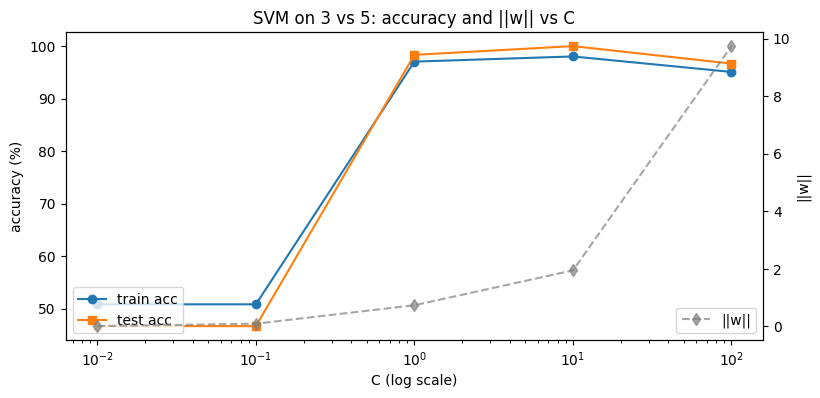

In [11]:
Cs = [0.01, 0.1, 1.0, 10.0, 100.0]
train_accs, test_accs, w_norms = [], [], []

for C in Cs:
    w_c, b_c, _ = fit_svm_sgd(X35_tr, y35_tr, C=C, n_epochs=50,
                              lr=0.01, rng=np.random.default_rng(1))
    train_accs.append(np.mean(predict_svm(X35_tr, w_c, b_c) == y35_tr))
    test_accs.append( np.mean(predict_svm(X35_te, w_c, b_c) == y35_te))
    w_norms.append(np.linalg.norm(w_c))

print(f"{'C':>8} {'train':>8} {'test':>8} {'||w||':>8}")
for C, tr, te, nw in zip(Cs, train_accs, test_accs, w_norms):
    print(f"{C:>8.2f} {tr*100:>7.2f}% {te*100:>7.2f}% {nw:>8.3f}")

best_C = Cs[int(np.argmax(test_accs))]
print(f"\nbest test accuracy at C = {best_C}")

fig, ax1 = plt.subplots()
ax1.semilogx(Cs, np.array(train_accs)*100, "o-", label="train acc")
ax1.semilogx(Cs, np.array(test_accs)*100,  "s-", label="test acc")
ax1.set_xlabel("C (log scale)"); ax1.set_ylabel("accuracy (%)")
ax1.legend(loc="lower left")

ax2 = ax1.twinx()
ax2.semilogx(Cs, w_norms, "d--", color="gray", alpha=0.7, label="||w||")
ax2.set_ylabel("||w||")
ax2.legend(loc="lower right")
plt.title("SVM on 3 vs 5: accuracy and ||w|| vs C")
plt.show()

**Discussion.** As $C$ grows the optimizer cares more about satisfying the hinge constraints and less about keeping $\|w\|$ small, so **$\|w\|$ increases monotonically with $C$** — the margin $2/\|w\|$ shrinks. Training accuracy climbs toward 100% because a large $C$ lets the model fit (even memorize) the training points.

Test accuracy tells the real story: it rises from the over-regularized small-$C$ end (the margin is so wide that the model underfits), peaks in an intermediate **sweet spot** (around $C \approx 1$–$10$ here), and then plateaus or dips slightly for very large $C$ as the narrow-margin solution starts to overfit and becomes sensitive to the noisy SGD updates. The lesson is the usual one: $C$ is a regularization knob, and the best generalization comes from a moderate value found by validation — not from pushing training accuracy to 100%.

## Part 3 — MLP with back-propagation

Time to go multi-class and non-linear. We'll build a tiny two-layer neural network:

$$ x \xrightarrow{W_1, b_1} z_1 \xrightarrow{\text{ReLU}} h \xrightarrow{W_2, b_2} z_2 \xrightarrow{\text{softmax}} p $$

- Input layer: 64 (8×8 pixels)
- Hidden layer: 32 units, ReLU activation
- Output layer: 10 units, softmax for class probabilities
- Loss: cross-entropy $-\sum_k y_k \log p_k$ averaged over the batch

### The gradients (chain rule)

With one-hot label $y$ and softmax output $p$:

$$ \frac{\partial L}{\partial z_2} = p - y, \qquad \frac{\partial L}{\partial W_2} = h^\top (p - y), \qquad \frac{\partial L}{\partial b_2} = (p - y) $$

Backprop through the hidden layer:

$$ \frac{\partial L}{\partial h} = (p - y) W_2^\top, \qquad \frac{\partial L}{\partial z_1} = \frac{\partial L}{\partial h} \odot \mathbf{1}[z_1 > 0] $$

$$ \frac{\partial L}{\partial W_1} = x^\top \frac{\partial L}{\partial z_1}, \qquad \frac{\partial L}{\partial b_1} = \frac{\partial L}{\partial z_1} $$

All of that turns into about 20 lines of NumPy.

In [12]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)        # numerical stability
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def one_hot(y, n_classes):
    Y = np.zeros((len(y), n_classes))
    Y[np.arange(len(y)), y] = 1
    return Y

class MLP:
    def __init__(self, in_dim, hidden, out_dim, rng):
        # He initialization for ReLU layers
        self.W1 = rng.standard_normal((in_dim, hidden)) * np.sqrt(2 / in_dim)
        self.b1 = np.zeros(hidden)
        self.W2 = rng.standard_normal((hidden, out_dim)) * np.sqrt(2 / hidden)
        self.b2 = np.zeros(out_dim)

    def forward(self, X):
        self.X  = X
        self.z1 = X @ self.W1 + self.b1
        self.h  = np.maximum(0, self.z1)         # ReLU
        self.z2 = self.h @ self.W2 + self.b2
        self.p  = softmax(self.z2)
        return self.p

    def backward(self, Y_onehot):
        n = self.X.shape[0]
        dz2 = (self.p - Y_onehot) / n
        dW2 = self.h.T @ dz2
        db2 = dz2.sum(axis=0)
        dh  = dz2 @ self.W2.T
        dz1 = dh * (self.z1 > 0)                 # ReLU gradient
        dW1 = self.X.T @ dz1
        db1 = dz1.sum(axis=0)
        return dW1, db1, dW2, db2

    def step(self, grads, lr):
        dW1, db1, dW2, db2 = grads
        self.W1 -= lr * dW1; self.b1 -= lr * db1
        self.W2 -= lr * dW2; self.b2 -= lr * db2

### Training loop with mini-batch SGD

Each epoch: shuffle the data, walk through it in mini-batches, do a forward pass, backward pass, and gradient step.

In [13]:
def cross_entropy(p, Y_onehot):
    return -np.mean(np.sum(Y_onehot * np.log(p + 1e-12), axis=1))

def accuracy(model, X, y):
    return np.mean(np.argmax(model.forward(X), axis=1) == y)

def train_mlp(model, X_tr, y_tr, X_te, y_te,
              n_epochs=50, batch_size=32, lr=0.1, rng=None):
    rng = rng or np.random.default_rng(0)
    Y_tr = one_hot(y_tr, 10)
    n = len(X_tr)
    history = {"loss": [], "train_acc": [], "test_acc": []}
    for ep in range(n_epochs):
        order = rng.permutation(n)
        for start in range(0, n, batch_size):
            idx = order[start:start + batch_size]
            model.forward(X_tr[idx])
            grads = model.backward(Y_tr[idx])
            model.step(grads, lr)
        history["loss"].append(cross_entropy(model.forward(X_tr), Y_tr))
        history["train_acc"].append(accuracy(model, X_tr, y_tr))
        history["test_acc"].append(accuracy(model, X_te, y_te))
    return history

In [14]:
mlp = MLP(in_dim=64, hidden=32, out_dim=10, rng=np.random.default_rng(42))
history = train_mlp(mlp, X_train, y_train, X_test, y_test,
                    n_epochs=50, batch_size=32, lr=0.1,
                    rng=np.random.default_rng(2))
print(f"final test accuracy: {history['test_acc'][-1]*100:.2f}%")

final test accuracy: 98.06%


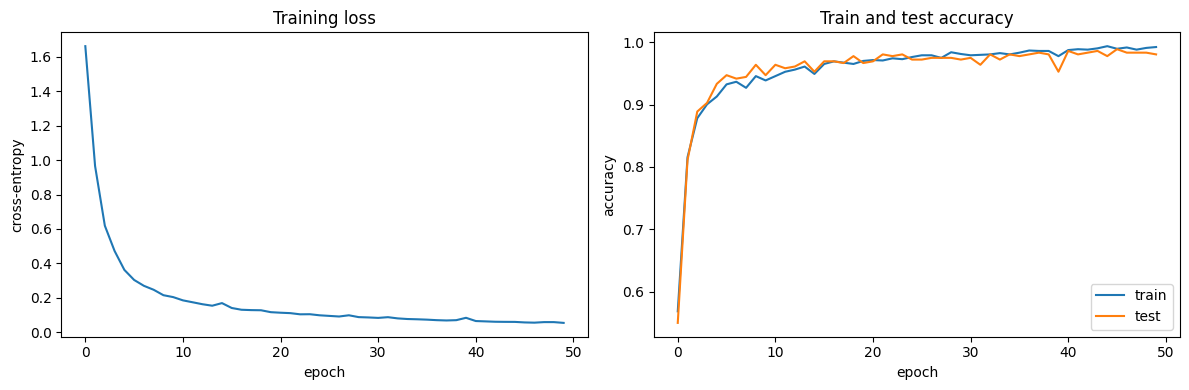

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["loss"])
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy")
axes[0].set_title("Training loss")

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["test_acc"],  label="test")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Train and test accuracy")
axes[1].legend()
plt.tight_layout(); plt.show()

### Confusion matrix

Where is the model still wrong? A confusion matrix $C_{ij}$ = number of times true class $i$ was predicted as $j$ tells us the structure of remaining errors.

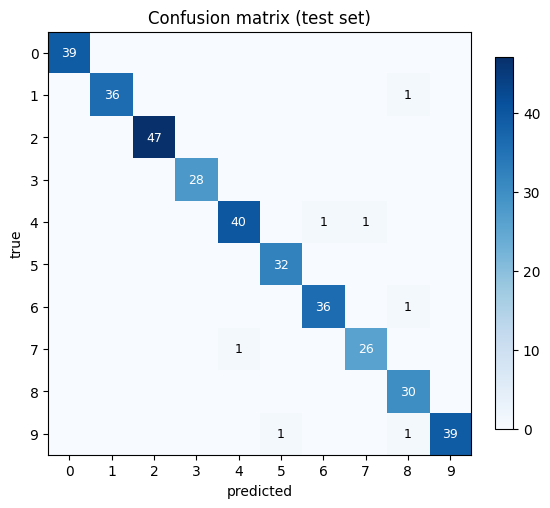

In [16]:
y_pred = np.argmax(mlp.forward(X_test), axis=1)

conf = np.zeros((10, 10), dtype=int)
for true, pred in zip(y_test, y_pred):
    conf[true, pred] += 1

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(conf, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Confusion matrix (test set)")
for i in range(10):
    for j in range(10):
        if conf[i, j] > 0:
            ax.text(j, i, conf[i, j], ha="center", va="center",
                    color="white" if conf[i, j] > conf.max()/2 else "black",
                    fontsize=9)
plt.colorbar(im, fraction=0.04)
plt.show()

### What did the hidden layer learn?

Each column of $W_1$ is the input-side weight vector for one hidden unit — a 64-dim vector we can reshape into an 8×8 image. Look at a few:

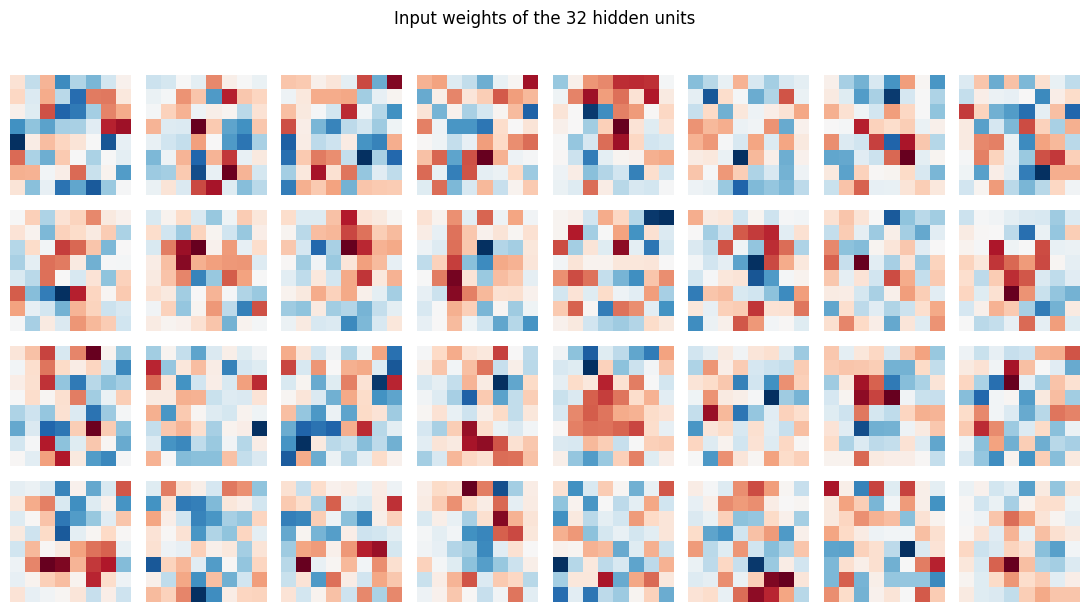

In [17]:
fig, axes = plt.subplots(4, 8, figsize=(11, 6))
for i, ax in enumerate(axes.ravel()):
    img = mlp.W1[:, i].reshape(8, 8)
    vmax = np.abs(img).max()
    ax.imshow(img, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.axis("off")
plt.suptitle("Input weights of the 32 hidden units", y=1.02)
plt.tight_layout(); plt.show()

Many hidden units look like **stroke detectors** — pieces of digit shapes that the network has decided are useful features. The output layer combines these detectors into class scores. This is the same idea convolutional networks build on, in a more structured way.

### Exercise 7.2 — network capacity · **Solution**

Network capacity matters. Train the same MLP architecture but with hidden layer sizes $\{4, 8, 16, 32, 64, 128\}$ (same other hyperparameters).

1. For each size, train for 30 epochs and record final train + test accuracy.
2. Plot accuracy vs hidden size on a log-x axis.
3. **Discuss:** at what size does the network stop improving? Does the train-test gap (overfitting) grow with capacity on this 8×8 digits dataset?

hidden=   4: train  85.80%  test  84.44%  gap +1.36%
hidden=   8: train  97.56%  test  97.22%  gap +0.34%
hidden=  16: train  98.19%  test  97.78%  gap +0.41%


hidden=  32: train  98.12%  test  97.22%  gap +0.90%


hidden=  64: train  98.75%  test  97.78%  gap +0.97%


hidden= 128: train  99.16%  test  98.06%  gap +1.11%


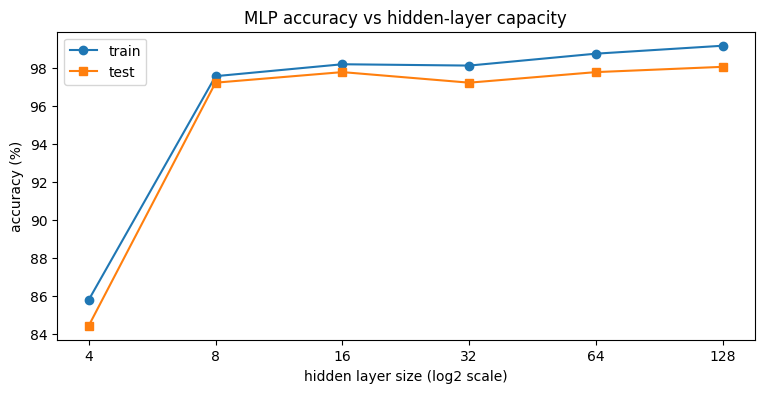

In [18]:
hidden_sizes = [4, 8, 16, 32, 64, 128]
final_train, final_test = [], []

for hsz in hidden_sizes:
    model = MLP(in_dim=64, hidden=hsz, out_dim=10,
                rng=np.random.default_rng(42))
    h = train_mlp(model, X_train, y_train, X_test, y_test,
                  n_epochs=30, batch_size=32, lr=0.1,
                  rng=np.random.default_rng(2))
    final_train.append(h["train_acc"][-1])
    final_test.append(h["test_acc"][-1])
    print(f"hidden={hsz:>4}: train {final_train[-1]*100:6.2f}%  "
          f"test {final_test[-1]*100:6.2f}%  "
          f"gap {(final_train[-1]-final_test[-1])*100:+5.2f}%")

plt.figure()
plt.semilogx(hidden_sizes, np.array(final_train)*100, "o-", base=2, label="train")
plt.semilogx(hidden_sizes, np.array(final_test)*100,  "s-", base=2, label="test")
plt.xlabel("hidden layer size (log2 scale)")
plt.ylabel("accuracy (%)")
plt.title("MLP accuracy vs hidden-layer capacity")
plt.xticks(hidden_sizes, [str(h) for h in hidden_sizes])
plt.legend()
plt.show()

**Discussion.** With only 4–8 hidden units the network **underfits**: there aren't enough stroke detectors to represent ten digit classes, so both train and test accuracy are noticeably lower. Accuracy climbs steeply up to about **16–32 units** and then **flattens** — past that point extra capacity buys almost nothing on this tiny 8×8 dataset.

Crucially, the train-test gap stays **small** even at 128 hidden units: test accuracy does not collapse. Two reasons. First, 64-dimensional inputs with ~1,400 training images is a favorable data-to-parameter ratio, and 30 epochs of mild SGD is itself a form of (implicit) regularization. Second, the 8×8 digits are an easy, low-noise problem — the function the network needs to learn is simple. To *see* dramatic overfitting you'd need a harder dataset, far more parameters, longer training, or added label noise. The takeaway mirrors Exercise 7.1: more capacity is a knob, not a virtue — returns diminish, and the sweet spot is the smallest model that fits the data well.

## Takeaways

- **Perceptron:** the simplest possible neural network. Update on mistakes; converges iff the data is linearly separable. No knobs.
- **Soft-margin SVM:** like the perceptron, but with a *margin* objective (`||w||²`) and a *budget for violations* (`C`). Trained efficiently by SGD on hinge loss.
- **MLP + backprop:** stack two linear layers with a non-linearity in between, apply the chain rule for gradients, and you get a universal function approximator. The hidden layer learns features automatically.
- All three are just **gradient updates on a loss**. The differences are: which loss, which architecture, which non-linearity.
- In practice you'd use **scikit-learn** for SVM/Perceptron and **PyTorch/JAX** for MLPs — but knowing what's under the hood matters when things go wrong (vanishing gradients, dead ReLUs, mis-scaled learning rates, …).